In [1]:
# Standard
import os
import pandas as pd
import numpy as np


#Plotting
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.impute import KNNImputer


In [2]:
def pls_reg_plots(df, ycol, xcol="C1",
                  xlabel="PLS C1 Gene Score",
                  base_color="#5B4B8A",
                  fig1=(4.5, 3.5),
                  fs_lab=16, fs_tick=13, 
                  outdir = None,):

    plt.figure(figsize=fig1)
    sns.regplot(x=df[xcol], y=df[ycol], lowess=False, color=base_color)

    X = sm.add_constant(df[[xcol, 'AgeDeath']])

    model = sm.OLS(df[ycol], X).fit()
    r2 = model.rsquared

    plt.text(
        0.05, 0.95,
        f"$R^2$ = {r2:.3f}",
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment="top"
    )

    plt.xlabel(xlabel, fontsize=fs_lab)
    plt.ylabel(ycol, fontsize=fs_lab)
    plt.xticks(fontsize=fs_tick)
    plt.yticks(fontsize=fs_tick)

    plt.tight_layout()
    if outdir:
        
        name = f'RegLM_{ycol}_C1.pdf'
        plt.savefig(os.path.join(outdir, name), dpi=300)
    
    plt.show()

In [3]:
def pls_sexreg_plots(df, ycol, xcol="C1", sexcol="sex",
                  xlabel="PLS C1 Gene Score",
                  base_color="#66c2a5", female_color="#e31a1c", male_color="#1f78b4",
                  fig2=(6.5, 3.5),
                  fs_lab=16, fs_tick=13, fs_leg=12):
    plt.figure(figsize=fig2)
    sns.regplot(data=df[df[sexcol] == 0], x=xcol, y=ycol,
                color=female_color, label="Female")
    sns.regplot(data=df[df[sexcol] == 1], x=xcol, y=ycol,
                color=male_color, label="Male")
    plt.xlabel(xlabel, fontsize=fs_lab)
    plt.ylabel(ycol, fontsize=fs_lab)
    plt.xticks(fontsize=fs_tick)
    plt.yticks(fontsize=fs_tick)
    plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
    plt.legend(title="Sex", fontsize=fs_leg, title_fontsize=fs_leg,
               loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
    plt.tight_layout()
    plt.show()

In [4]:
def save_pretty_table_png(
    df, out_png="tau_table.png",
    title=None,
    sig_col="sig",
    max_rows=15,
    dpi=300
):
    # Keep top rows
    d = df.head(max_rows).copy()

    # Pull sig flags and drop from display
    sig = None
    if sig_col in d.columns:
        sig = d[sig_col].values
        d = d.drop(columns=[sig_col])

    nrows, ncols = d.shape

    # Figure size heuristic: scale with rows/cols
    fig_w = 1.1 * ncols + 3.0
    fig_h = 0.42 * (nrows + 1) + (0.8 if title else 0.2)

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis("off")

    if title:
        ax.text(
            0.1, 1.03, title,
            transform=ax.transAxes,
            ha="left", va="bottom",
            fontsize=16, fontweight="bold"
        )

    tbl = ax.table(
        cellText=d.values,
        colLabels=d.columns,
        cellLoc="center",
        colLoc="center",
        loc="upper left",
        bbox=[0, 0, 1, 1]
    )

    # Manually adjust column widths 
    col_widths = [0.38, 0.12, 0.20, 0.10, 0.12]

    for i, width in enumerate(col_widths):
        for r in range(nrows + 1):
            tbl[(r, i)].set_width(width)

    # Global font and scale
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(12)
    tbl.scale(1, 1.35)
    

    # Styling
    for (r, c), cell in tbl.get_celld().items():
        # Remove full grid
        cell.set_linewidth(0.0)

        # Header row
        if r == 0:
            cell.set_text_props(weight="bold")
            cell.set_facecolor("#F2F2F2")
        else:
            # Zebra stripes
            cell.set_facecolor("#FFFFFF" if r % 2 else "#FAFAFA")

            # Left align region names
            if c == 0:
                cell._loc = "left"
                cell.PAD = 0.02
                cell.set_text_props(ha="left")

            # Highlight sig rows
            if sig is not None and sig[r-1]:
                # tint on sig rows
                cell.set_facecolor("#EEF5FF")

    # Add a thin line under header
    for c in range(ncols):
        cell = tbl[(0, c)]
        cell.visible_edges = "B"
        cell.set_linewidth(1.2)
        cell.set_edgecolor("#D0D0D0")

    plt.tight_layout()
    fig.savefig(out_png, dpi=dpi, bbox_inches="tight", transparent=True)
    plt.close(fig)
    return out_png

def make_display_table(df):
    out = df.copy()
    out = out.sort_values("R2", ascending=False)

    out["CI_95"] = out.apply(lambda r: f"[{r['CI_low']:.2f}, {r['CI_high']:.2f}]", axis=1)
    out["R2"]     = out["R2"].map(lambda x: f"{x:.2f}")
    out["FDR p"]  = out["FDR_p"].map(lambda x: f"{x:.2e}")
    out["beta (C1)"] = out["beta_C1"].map(lambda x: f"{x:.2f}")

    # Keep only display columns and order them
    out = out[["Region", "CI_95", "R2", "FDR p", "beta (C1)"]]

    return out.reset_index(drop=True)

In [5]:
region_map = {
    "hip":  "Hippocampus (CA1)",
    "ec":   "Entorhinal cortex",
    "mt":   "Midtemporal cortex",
    "mes_t":"Mesial temporal",
    "ag":   "Angular gyrus (inferior parietal)",
    "mf":   "Midfrontal cortex",
    "sf":   "Superior frontal gyrus",
    "cg":   "Anterior cingulate cortex",
    "calc": "Calcarine cortex",
    "it":   "Inferior temporal cortex",
    }

def parse_var(v):
    v = str(v).strip().lower()

    # global vars
    if v == "nft":
        return ("NFT", "Burden across regions")
    if v in ["tangsqrt"]:
        return ("Tangles", "Burden across regions")
    if v in ["amylsqrt"]:
        return ("Amyloid_tot", "Burden across regions")
    if v == "plaq_n":
        return ("amyloid_neuritic", "Burden across regions")
    if v == "plaq_d":
        return ("amyloid_diffuse", "Burden across regions")

    # regional tau
    if v.startswith("nft_"):
        key = v.split("nft_")[1]
        return ("NFT", region_map.get(key, key))

    if v.startswith("tangles_"):
        key = v.split("tangles_")[1]
        return ("Tangles", region_map.get(key, key))

    # regional amyloid
    if v.startswith("amyloid_"):
        key = v.split("amyloid_")[1]
        return ("Amyloid_tot", region_map.get(key, key))

    # regional plaques
    if v.startswith("plaq_n_"):
        key = v.split("plaq_n_")[1]
        return ("amyloid_neuritic", region_map.get(key, key))

    if v.startswith("plaq_d_"):
        key = v.split("plaq_d_")[1]
        return ("amyloid_diffuse", region_map.get(key, key))

In [6]:
# Directories MacOS
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'

# Directories Windows
#main_dir = 'C:\\Users\\gabri\\Documents\\Data_projects\\MCcharactertization\\ROSMAP\\Top_sets\\Set309'
#core_dir = 'C:\\Users\\gabri\\Documents\\Data_projects\\MCcharactertization\\ROSMAP\\_core_data'


df_plot = pd.read_csv(os.path.join(main_dir, "_set_data/PLSX_scores_pheno.csv"), index_col=0)
fullpheno = pd.read_excel(os.path.join(core_dir, 'dataset_1125_basic_01102022.xlsx'), index_col='projid')
fullpheno, df_plot = fullpheno.align(df_plot, join='inner', axis=0)


fig_dir = os.path.join(main_dir, "Regional_LMs")
if not os.path.exists(fig_dir):
    os.makedirs(fig_dir)

In [7]:
tau_cols = ['nft', 'nft_ag', 'nft_ec', 'nft_hip', 'nft_mf', 'nft_mt',
    'tangles_ag', 'tangles_calc', 'tangles_cg', 'tangles_ec',
    'tangles_hip', 'tangles_it', 'tangles_mf', 'tangles_sf', 'tangsqrt']

amyloid_cols = ['plaq_d_ag', 'plaq_d_ec', 'plaq_d_hip', 'plaq_d_mf', 'plaq_d_mt',
                'amyloid_ag', 'amyloid_calc', 'amyloid_cg', 'amyloid_ec', 'amyloid_hip', 
                'amyloid_it', 'amyloid_mes_t', 'amyloid_mf', 'amyloid_sf', 'amylsqrt', 
                'plaq_d', 'plaq_n', 'plaq_n_ag', 'plaq_n_ec', 'plaq_n_hip', 'plaq_n_mf',
                'plaq_n_mt']

path_cols = tau_cols + amyloid_cols
df_new = pd.concat([df_plot, fullpheno[tau_cols+amyloid_cols]], axis=1)


In [8]:
# Impute missing values with KNN imputer
path_cols = [c for c in (tau_cols + amyloid_cols) if c in df_new.columns]
sub = df_new[path_cols].apply(pd.to_numeric)

imputer = KNNImputer(n_neighbors=5)
imputed_arr = imputer.fit_transform(sub)
imputed_df = pd.DataFrame(imputed_arr, index=sub.index, columns=sub.columns)
df_new[path_cols] = imputed_df[path_cols]


# Log-transform regional burden variables
log_cols = [c for c in path_cols if c not in ["tangsqrt", "amylsqrt"]]
df_new[log_cols] = np.log1p(df_new[log_cols])

# Map categorical variables to numeric
df_new["sex"] = df_new["sex"].map({"Female": 0,"Male": 1})
df_new["E2"] = df_new["E2"].map({"No copies": 0,"E2": 1})
df_new["E4"] = df_new["E4"].map({"No copies": 0,"E4": 1})

## Regional pathology LMs

## Tau Tangles

In [9]:
# Tangles and NFT LM with Age-at-Death covariate
tau_res = []

for col in tau_cols:
    y = df_new[col]
    x = sm.add_constant(df_new[['C1', 'AgeDeath', 'sex']])
    model = sm.OLS(y, x).fit()
    ci_low, ci_high = model.conf_int().loc['C1']
    tau_res.append({
        'variable': col,
        'beta_C1': model.params['C1'],
        'p_value': model.pvalues['C1'],
        'CI_low': ci_low,
        'CI_high': ci_high,
        'beta_age': model.params['AgeDeath'],
        'p_age': model.pvalues['AgeDeath'],
        'beta_sex': model.params['sex'],
        'p_sex': model.pvalues['sex'],
        'R2': model.rsquared
    })

taures_df = (pd.DataFrame(tau_res).sort_values("R2", ascending=False).reset_index(drop=True))
taures_df["FDR_p"] = multipletests(taures_df["p_value"], method="fdr_bh")[1]
taures_df[["Measure", "Region"]] = taures_df["variable"].apply(lambda x: pd.Series(parse_var(x)))

taures_df

,variable,beta_C1,p_value,CI_low,CI_high,beta_age,p_age,beta_sex,p_sex,R2,FDR_p,Measure,Region
0,tangles_it,0.158607,2.014324e-10,0.111638,0.205576,0.029021,0.014391,-0.162738,0.280324,0.208517,1.510743e-09,Tangles,Inferior temporal cortex
1,tangsqrt,0.166865,8.720627e-11,0.118508,0.215223,0.022822,0.060889,-0.156736,0.312456,0.202267,1.308094e-09,Tangles,Burden across regions
2,nft,0.047028,1.102442e-09,0.032440,0.061617,0.008379,0.022787,-0.034003,0.467381,0.188170,5.512210e-09,NFT,Burden across regions
3,nft_hip,0.166703,6.341105e-09,0.112237,0.221169,0.047074,0.000667,0.132633,0.447706,0.188078,1.585276e-08,NFT,Hippocampus (CA1)
4,nft_mt,0.144110,2.729927e-09,0.098214,0.190007,0.015930,0.167335,-0.302593,0.040598,0.187008,1.023723e-08,NFT,Midtemporal cortex
5,tangles_ec,0.117426,1.126474e-08,0.078361,0.156491,0.031439,0.001505,0.104942,0.402348,0.177969,2.112139e-08,Tangles,Entorhinal cortex
6,tangles_cg,0.105622,3.972377e-09,0.071603,0.139641,0.011984,0.161098,-0.178511,0.102595,0.176846,1.191713e-08,Tangles,Anterior cingulate cortex
7,tangles_hip,0.129255,9.825247e-08,0.082972,0.175538,0.040232,0.000622,0.003573,0.980786,0.174613,1.473787e-07,Tangles,Hippocampus (CA1)
8,nft_ec,0.116485,2.828626e-07,0.073090,0.159879,0.039849,0.000306,0.191337,0.169813,0.164861,3.535782e-07,NFT,Entorhinal cortex
9,tangles_sf,0.109213,7.569933e-09,0.073333,0.145092,0.003607,0.688666,-0.224968,0.051393,0.164573,1.622128e-08,Tangles,Superior frontal gyrus


In [10]:
nft_tab     = make_display_table(taures_df[taures_df["Measure"] == "NFT"])
tangles_tab = make_display_table(taures_df[taures_df["Measure"] == "Tangles"])

save_pretty_table_png(nft_tab,
    out_png=(os.path.join(fig_dir, f'Region_NFT_LMres.png')),
    title="PLSX1 associations with regional neurofibrillary \n tangles (NFTs) (age-adjusted)",
    max_rows=15,
    dpi=300
    )

save_pretty_table_png(tangles_tab,
    out_png=(os.path.join(fig_dir, f'Region_tangles_LMres.png')),
    title="PLSX1 associations with regional tau tangles (age-adjusted)",
    max_rows=15,
    dpi=300
    )

'/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/Regional_LMs/Region_tangles_LMres.png'

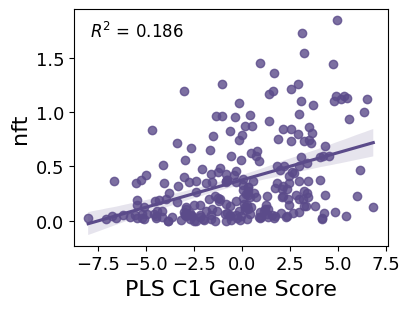

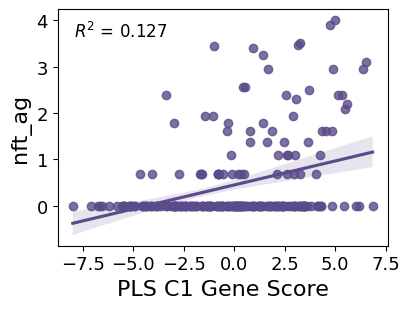

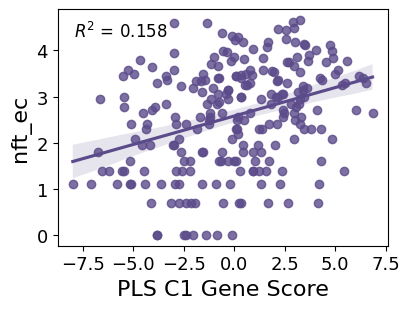

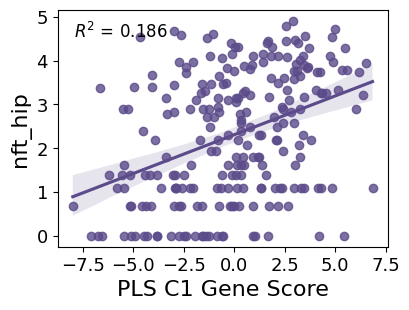

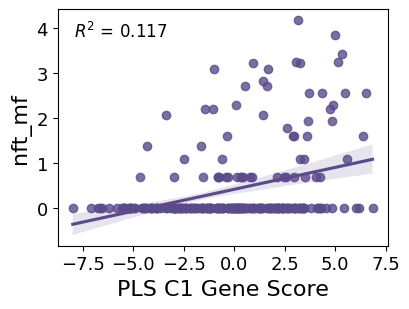

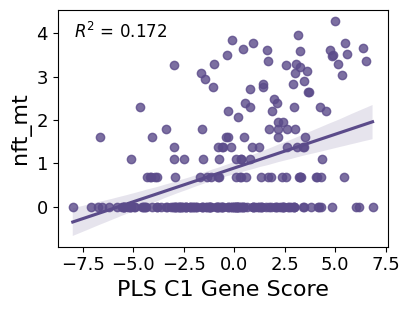

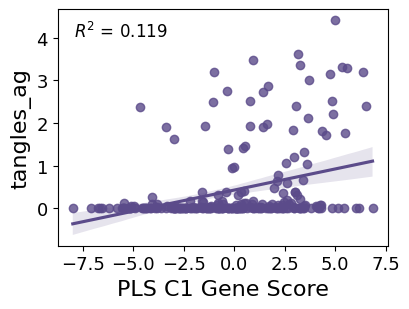

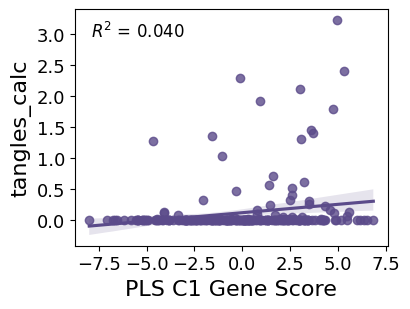

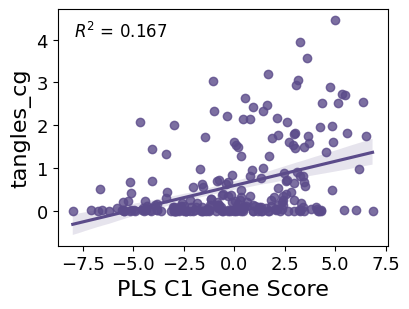

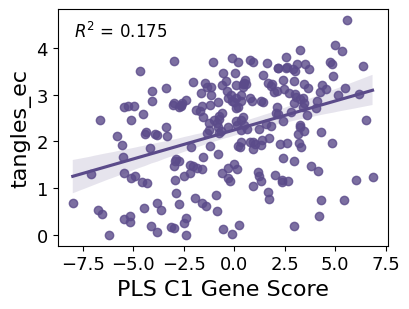

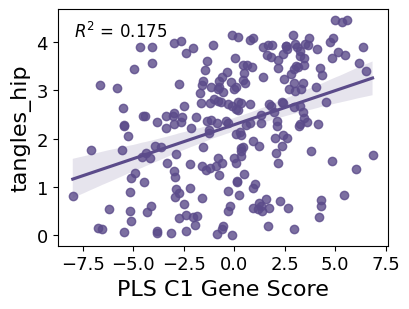

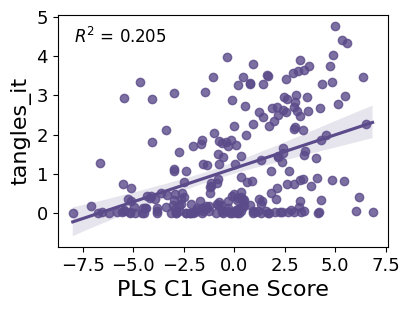

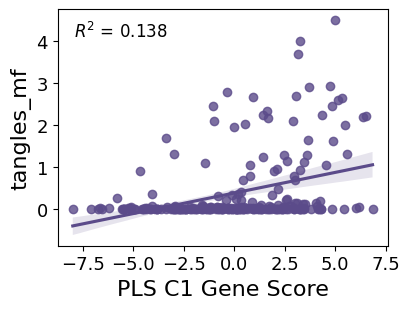

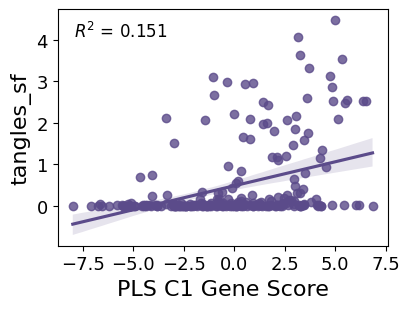

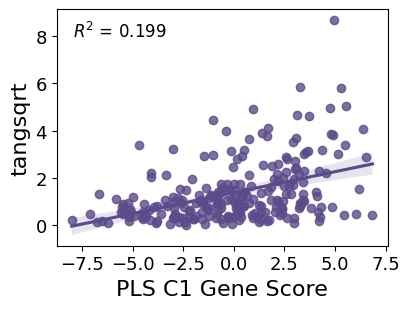

In [11]:
for col in tau_cols:
    pls_reg_plots(df_new, ycol=col, xcol="C1",
                  xlabel="PLS C1 Gene Score",
                  fig1=(4.2, 3.2),
                  outdir=fig_dir)

## Amyloid and plaques (neuritic and diffuse)

In [12]:
# Amyloid and plaques LM
amy_res = []

for col in amyloid_cols:
    y = df_new[col]

    # predictors
    x = df_new[['C1', 'AgeDeath', 'sex']]
    x = sm.add_constant(x)
    model = sm.OLS(y, x).fit()

    amy_res.append({
        'variable': col,
        'beta_C1': model.params['C1'],
        'p_value': model.pvalues['C1'],
        'CI_low': ci_low,
        'CI_high': ci_high,
        'beta_age': model.params['AgeDeath'],
        'p_age': model.pvalues['AgeDeath'],
        'beta_sex': model.params['sex'],
        'p_sex': model.pvalues['sex'],
        'R2': model.rsquared
    })

amyres_df = pd.DataFrame(amy_res).sort_values("R2", ascending=False).reset_index(drop=True)
amyres_df["FDR_p"] = multipletests(amyres_df["p_value"], method="fdr_bh")[1]

amyres_df[["Measure", "Region"]] = amyres_df["variable"].apply(lambda x: pd.Series(parse_var(x)))

amyres_df

,variable,beta_C1,p_value,CI_low,CI_high,beta_age,p_age,beta_sex,p_sex,R2,FDR_p,Measure,Region
0,amyloid_mes_t,0.107629,6.216671e-11,0.118508,0.215223,0.020026,0.010366,-0.085127,0.390846,0.215917,6.838338e-10,Amyloid_tot,Mesial temporal
1,amylsqrt,0.156786,2.038037e-10,0.118508,0.215223,0.029809,0.011055,-0.144192,0.333239,0.208789,1.120921e-09,Amyloid_tot,Burden across regions
2,amyloid_ec,0.116100,8.027246e-10,0.118508,0.215223,0.025722,0.004403,-0.102205,0.372114,0.205057,2.207493e-09,Amyloid_tot,Entorhinal cortex
3,plaq_n_mt,0.176212,1.893831e-10,0.118508,0.215223,0.030280,0.021232,-0.125784,0.451584,0.201472,1.120921e-09,amyloid_neuritic,Midtemporal cortex
4,amyloid_cg,0.136826,5.152749e-10,0.118508,0.215223,0.025487,0.015112,-0.110738,0.406097,0.198065,1.619435e-09,Amyloid_tot,Anterior cingulate cortex
5,amyloid_mf,0.130608,5.012503e-10,0.118508,0.215223,0.026459,0.008258,-0.036060,0.776552,0.196156,1.619435e-09,Amyloid_tot,Midfrontal cortex
6,amyloid_hip,0.092891,4.219098e-11,0.118508,0.215223,0.009455,0.154827,-0.040911,0.629311,0.193537,6.838338e-10,Amyloid_tot,Hippocampus (CA1)
7,plaq_n,0.056004,3.358154e-10,0.118508,0.215223,0.005333,0.206768,-0.087600,0.105006,0.192232,1.477588e-09,amyloid_neuritic,Burden across regions
8,plaq_n_mf,0.155321,3.935381e-09,0.118508,0.215223,0.021542,0.086943,-0.346467,0.031509,0.192162,7.870761e-09,amyloid_neuritic,Midfrontal cortex
9,amyloid_ag,0.125481,2.140577e-09,0.118508,0.215223,0.021659,0.030371,-0.182909,0.151288,0.191745,4.709270e-09,Amyloid_tot,Angular gyrus (inferior parietal)


In [13]:
amyloid_tab = make_display_table(amyres_df[amyres_df["Measure"] == "Amyloid_tot"])
diffuse_tab = make_display_table(amyres_df[amyres_df["Measure"] == "amyloid_diffuse"])
neuritic_tab = make_display_table(amyres_df[amyres_df["Measure"] == "amyloid_neuritic"])


save_pretty_table_png(amyloid_tab,out_png=(os.path.join(fig_dir, f'Region_amyloid_LMres.png')),
                      title="PLSX1 associations with regional amyloid (age-adjusted)",
                      max_rows=15, dpi=300)

save_pretty_table_png(diffuse_tab, out_png=(os.path.join(fig_dir, f'Region_plaqdiffuse_LMres.png')),
                      title="PLSX1 associations with regional amyloid plaques \n (diffuse) (age-adjusted)",
                      max_rows=15, dpi=300)

save_pretty_table_png(neuritic_tab,out_png=(os.path.join(fig_dir, f'Region_plaqneuritic_LMres.png')),
                      title="PLSX1 associations with regional amyloid plaques \n (neuritic) (age-adjusted)",
                      max_rows=15,dpi=300)

'/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/Regional_LMs/Region_plaqneuritic_LMres.png'

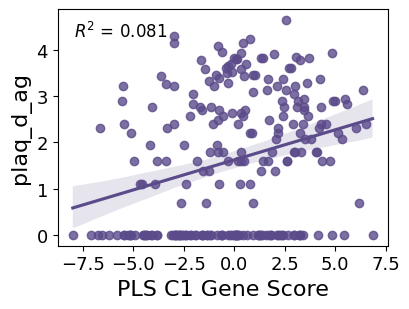

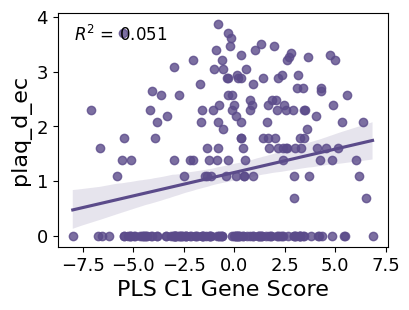

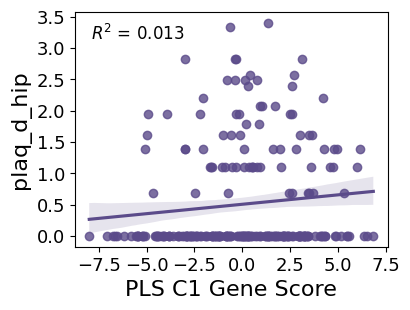

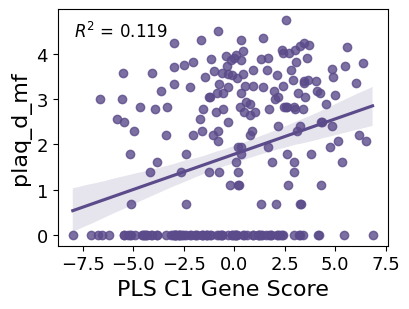

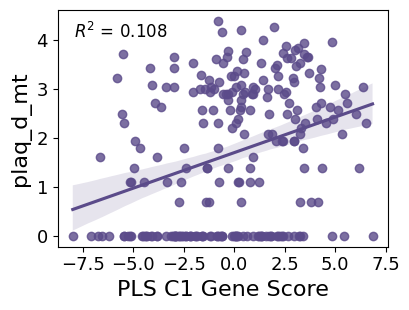

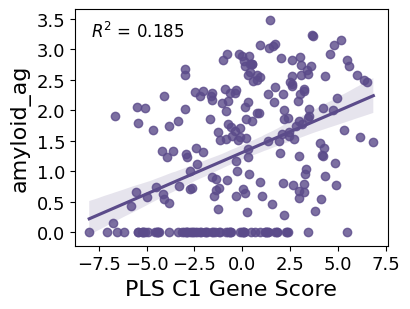

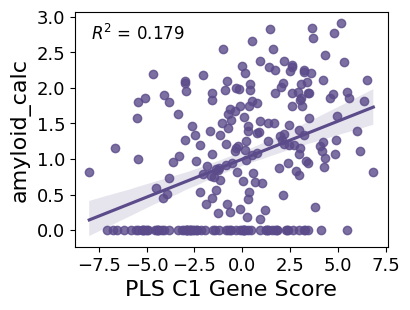

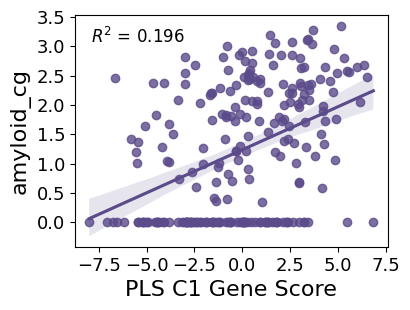

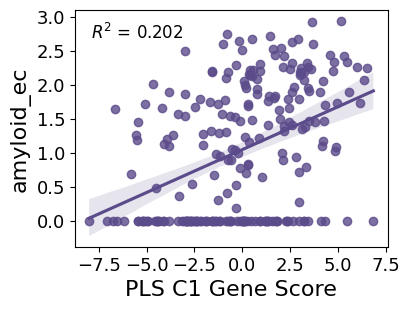

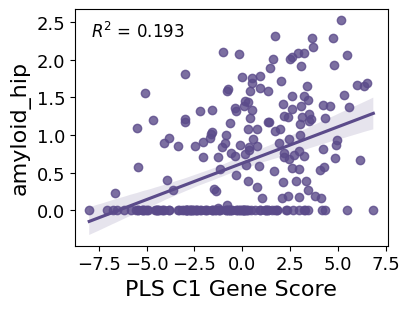

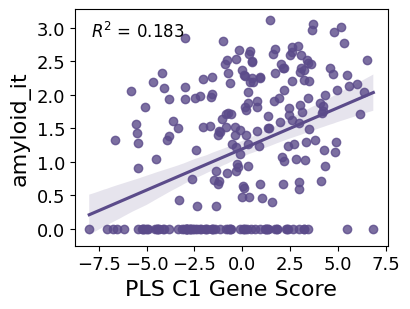

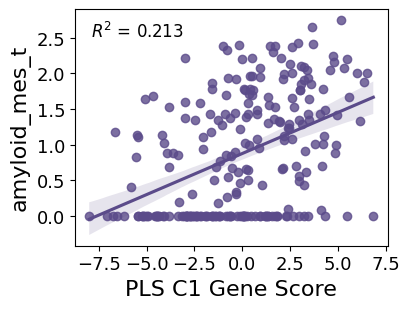

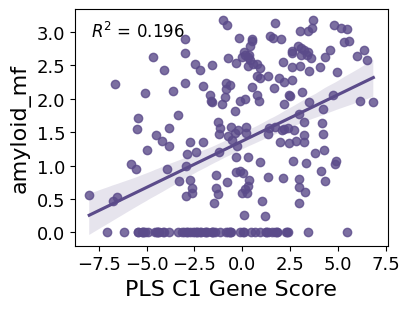

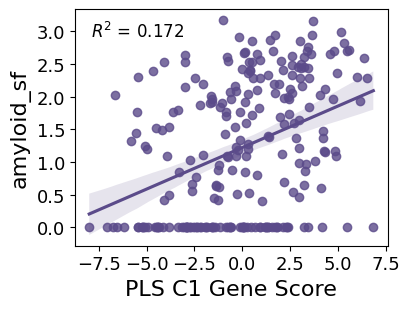

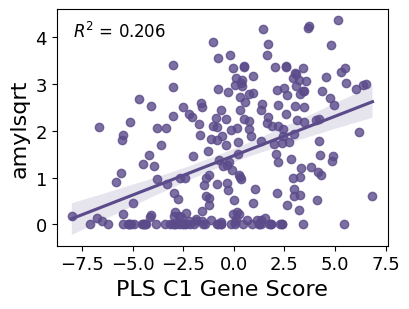

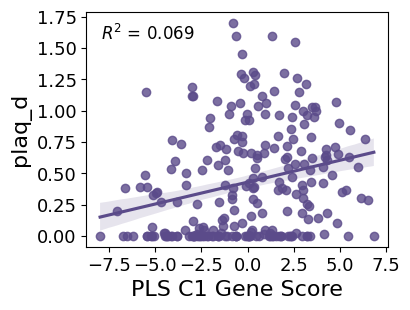

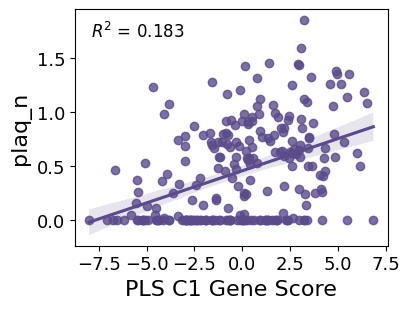

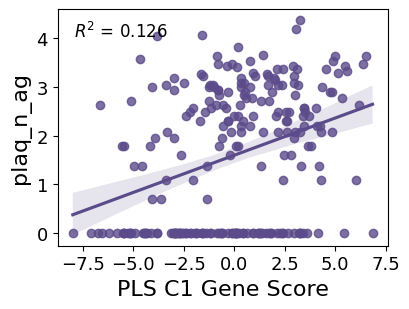

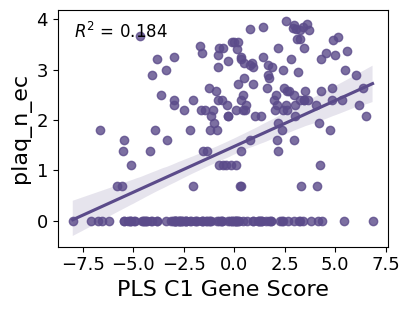

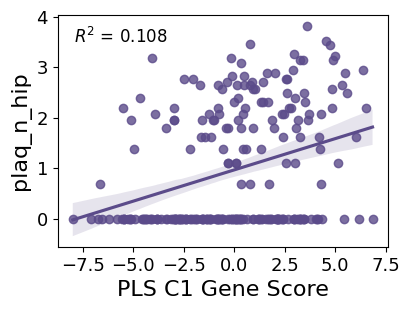

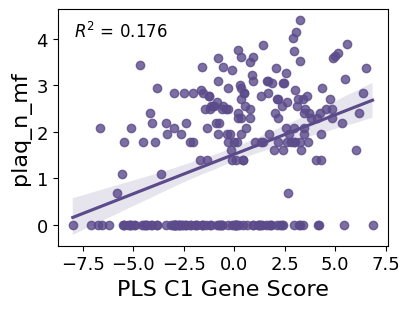

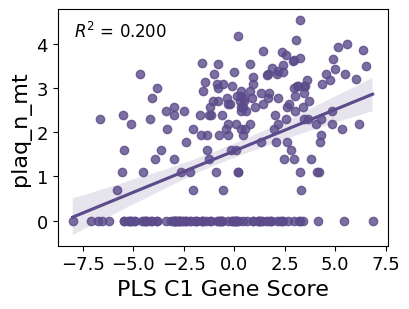

In [14]:
for col in amyloid_cols:
    pls_reg_plots(df_new, ycol=col, xcol="C1",
                  xlabel="PLS C1 Gene Score",
                  fig1=(4.2, 3.2),
                  outdir=fig_dir)